# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# Notebook không phụ thuộc đường dẫn cá nhân; có thể chạy trực tiếp trong Jupyter hoặc Colab.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


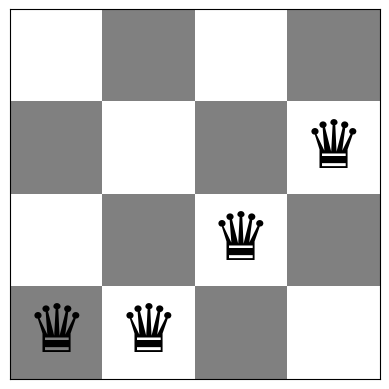

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


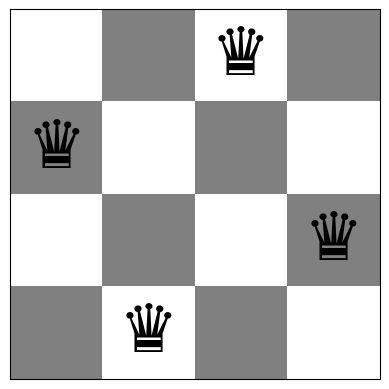

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [5]:
def steepest_hill_climbing(board, max_steps=10000):
    """Chọn láng giềng có số xung đột thấp nhất; dừng khi không cải thiện."""
    current = np.array(board, dtype=int).copy()
    history = [conflicts(current)]
    evaluations = 0
    for _ in range(max_steps):
        best_board, best_h = current.copy(), history[-1]
        for col in range(len(current)):
            for row in range(len(current)):
                if row == current[col]: continue
                neighbor = current.copy(); neighbor[col] = row
                h = conflicts(neighbor); evaluations += 1
                if h < best_h: best_board, best_h = neighbor, h
        if best_h >= history[-1]: break
        current = best_board; history.append(best_h)
        if best_h == 0: break
    return current, history, evaluations


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
def inefficient_stochastic_hill_climbing(board, max_steps=10000):
    """Đánh giá mọi láng giềng rồi chọn ngẫu nhiên trong các nước cải thiện."""
    current = np.array(board, dtype=int).copy()
    history = [conflicts(current)]; evaluations = 0
    for _ in range(max_steps):
        current_h = history[-1]; improving = []
        for col in range(len(current)):
            for row in range(len(current)):
                if row == current[col]: continue
                neighbor = current.copy(); neighbor[col] = row
                h = conflicts(neighbor); evaluations += 1
                if h < current_h: improving.append((neighbor, h))
        if not improving: break
        current, h = improving[np.random.randint(len(improving))]
        history.append(h)
        if h == 0: break
    return current, history, evaluations


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
def efficient_stochastic_hill_climbing(board, max_steps=10000, patience=None):
    """Thử một láng giềng ngẫu nhiên mỗi lần; dừng sau nhiều lần không cải thiện."""
    current = np.array(board, dtype=int).copy(); size = len(current)
    if patience is None: patience = max(100, 5 * size * (size - 1))
    history = [conflicts(current)]; evaluations = 0; no_improve = 0
    for _ in range(max_steps):
        col = np.random.randint(size)
        row = np.random.randint(size - 1)
        if row >= current[col]: row += 1
        neighbor = current.copy(); neighbor[col] = row
        h = conflicts(neighbor); evaluations += 1
        if h < history[-1]:
            current = neighbor; history.append(h); no_improve = 0
            if h == 0: break
        else:
            no_improve += 1
            if no_improve >= patience: break
    return current, history, evaluations


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
def random_restart_hill_climbing(n, algorithm, restarts=100, max_steps=10000):
    """Chạy thuật toán nhiều lần từ các bàn cờ ngẫu nhiên."""
    best_board, best_history, best_h = None, None, float('inf')
    total_evaluations = 0
    for _ in range(restarts):
        board, history, evaluations = algorithm(random_board(n), max_steps=max_steps)
        total_evaluations += evaluations; h = conflicts(board)
        if h < best_h: best_board, best_history, best_h = board.copy(), history, h
        if best_h == 0: break
    return best_board, best_history, total_evaluations


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [9]:
def simulated_annealing(board, max_steps=20000, initial_temperature=5.0, cooling_rate=0.9995):
    """Cho phép nước đi xấu với xác suất exp(-delta/T), nhiệt độ giảm dần."""
    current = np.array(board, dtype=int).copy()
    current_h = conflicts(current); best = current.copy(); best_h = current_h
    history = [current_h]; evaluations = 0; temperature = initial_temperature
    size = len(current)
    for step in range(max_steps):
        col = np.random.randint(size)
        row = np.random.randint(size - 1)
        if row >= current[col]: row += 1
        neighbor = current.copy(); neighbor[col] = row
        h = conflicts(neighbor); evaluations += 1
        delta = h - current_h
        if delta <= 0 or np.random.random() < np.exp(-delta / max(temperature, 1e-12)):
            current, current_h = neighbor, h
        if current_h < best_h:
            best, best_h = current.copy(), current_h
        history.append(best_h)
        temperature *= cooling_rate
        if best_h == 0: break
    return best, history, evaluations


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Code bên dưới chạy 100 lượt cho mỗi thuật toán và kích thước n=4, n=8. Mỗi lượt dùng bàn cờ khởi tạo ngẫu nhiên; tỷ lệ thành công được tính bằng phần trăm lượt có h=0. Thời gian phụ thuộc máy và môi trường chạy.

Add the used code here:

In [10]:
# Bài 8 / Task 6: tối thiểu 100 lượt cho n=4 và n=8
import time
import pandas as pd

algorithms = {
    'Steepest HC': steepest_hill_climbing,
    'Inefficient Stochastic HC': inefficient_stochastic_hill_climbing,
    'Efficient Stochastic HC': efficient_stochastic_hill_climbing,
    'Simulated Annealing': simulated_annealing,
}

def benchmark(n_queens, algorithm, runs=100):
    records = []
    for _ in range(runs):
        start_board = random_board(n_queens)
        start = time.perf_counter()
        final_board, history, evaluations = algorithm(start_board)
        elapsed = time.perf_counter() - start
        final_h = int(conflicts(final_board))
        records.append({
            'time_s': elapsed,
            'final_conflicts': final_h,
            'success': final_h == 0,
            'evaluations': evaluations,
        })
    df = pd.DataFrame(records)
    return {
        'algorithm': algorithm.__name__,
        'n': n_queens,
        'runs': runs,
        'avg_time_s': df['time_s'].mean(),
        'avg_final_conflicts': df['final_conflicts'].mean(),
        'success_rate_pct': 100 * df['success'].mean(),
        'avg_evaluations': df['evaluations'].mean(),
    }

results = []
for size in (4, 8):
    for name, algorithm in algorithms.items():
        print(f'Đang chạy {name}, n={size} ...')
        results.append(benchmark(size, algorithm, runs=100))

results_df = pd.DataFrame(results)
display(results_df.round(5))


Đang chạy Steepest HC, n=4 ...
Đang chạy Inefficient Stochastic HC, n=4 ...
Đang chạy Efficient Stochastic HC, n=4 ...
Đang chạy Simulated Annealing, n=4 ...
Đang chạy Steepest HC, n=8 ...
Đang chạy Inefficient Stochastic HC, n=8 ...
Đang chạy Efficient Stochastic HC, n=8 ...
Đang chạy Simulated Annealing, n=8 ...


,algorithm,n,runs,avg_time_s,avg_final_conflicts,success_rate_pct,avg_evaluations
0,steepest_hill_climbing,4,100,0.00011,0.53,49.0,25.44
1,inefficient_stochastic_hill_climbing,4,100,0.00015,0.75,36.0,31.44
2,efficient_stochastic_hill_climbing,4,100,0.00069,0.78,35.0,77.48
3,simulated_annealing,4,100,0.00112,0.00,100.0,98.18
4,steepest_hill_climbing,8,100,0.00184,1.21,17.0,229.60
5,inefficient_stochastic_hill_climbing,8,100,0.00261,1.36,13.0,317.52
6,efficient_stochastic_hill_climbing,8,100,0.00399,1.39,12.0,314.79
7,simulated_annealing,8,100,0.05143,0.00,100.0,4111.11


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.
Các đường biểu diễn số xung đột tốt nhất theo từng bước/lần cải thiện. Với thuật toán ngẫu nhiên, đường hội tụ có thể khác nhau giữa các lần chạy.

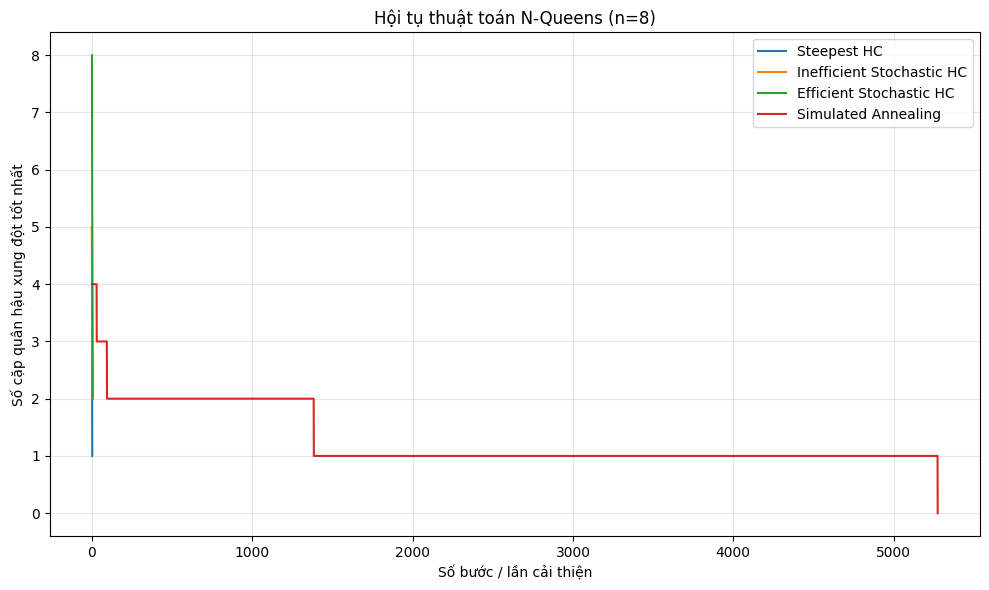

Nhận xét:
- Steepest HC đánh giá toàn bộ láng giềng nên mỗi vòng tốn nhiều phép tính, nhưng chọn được bước cải thiện tốt nhất.
- Inefficient Stochastic HC cũng duyệt toàn bộ láng giềng, sau đó chọn ngẫu nhiên một bước cải thiện.
- Efficient Stochastic HC chỉ thử một láng giềng mỗi lần nên rẻ hơn, nhưng có thể dừng ở cực trị cục bộ.
- Simulated Annealing có thể chấp nhận bước xấu lúc nhiệt độ cao, giúp thoát một số cực trị cục bộ; kết quả phụ thuộc lịch làm nguội.


In [11]:
# Đồ thị hội tụ cho một lượt chạy đại diện ở n=8
plt.figure(figsize=(10, 6))
representative_histories = {}
for name, algorithm in algorithms.items():
    board, history, evaluations = algorithm(random_board(8))
    representative_histories[name] = history
    plt.plot(range(len(history)), history, label=name)
plt.xlabel('Số bước / lần cải thiện')
plt.ylabel('Số cặp quân hậu xung đột tốt nhất')
plt.title('Hội tụ thuật toán N-Queens (n=8)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Nhận xét:')
print('- Steepest HC đánh giá toàn bộ láng giềng nên mỗi vòng tốn nhiều phép tính, nhưng chọn được bước cải thiện tốt nhất.')
print('- Inefficient Stochastic HC cũng duyệt toàn bộ láng giềng, sau đó chọn ngẫu nhiên một bước cải thiện.')
print('- Efficient Stochastic HC chỉ thử một láng giềng mỗi lần nên rẻ hơn, nhưng có thể dừng ở cực trị cục bộ.')
print('- Simulated Annealing có thể chấp nhận bước xấu lúc nhiệt độ cao, giúp thoát một số cực trị cục bộ; kết quả phụ thuộc lịch làm nguội.')


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.
Lưu ý: thời gian đo là thời gian thực nghiệm và có nhiễu; số mũ log-log chỉ mô tả dữ liệu đo được, không phải chứng minh độ phức tạp lý thuyết.

algorithm,Efficient Stochastic HC,Steepest HC
n,,
4,0.001159,0.000168
8,0.003514,0.001482
12,0.013186,0.007729
16,0.031825,0.029428
20,0.053386,0.075990


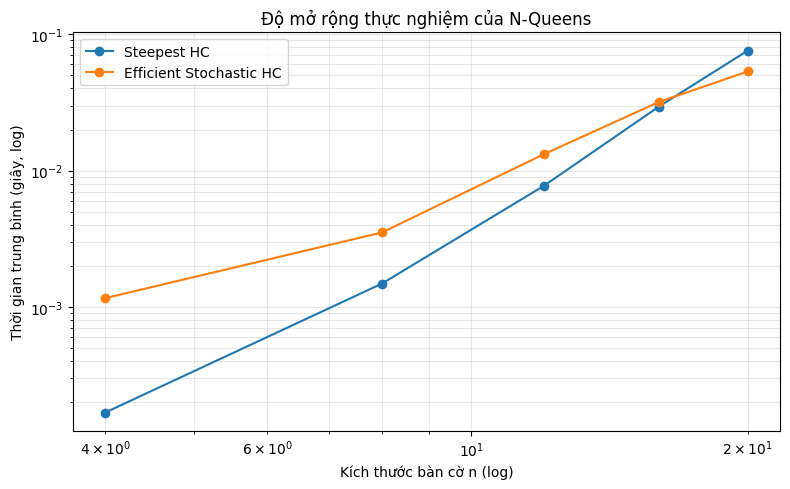

Steepest HC: số mũ thực nghiệm p ≈ 3.82; đây là ước lượng theo các kích thước đã thử, không phải chứng minh Big-O.
Efficient Stochastic HC: số mũ thực nghiệm p ≈ 2.46; đây là ước lượng theo các kích thước đã thử, không phải chứng minh Big-O.


In [12]:
# Biểu đồ log-log thời gian chạy theo kích thước bàn cờ
# Dùng ít nhất hai thuật toán; 10 lượt mỗi kích thước để giữ thời gian chạy hợp lý.
scaling_algorithms = {
    'Steepest HC': steepest_hill_climbing,
    'Efficient Stochastic HC': efficient_stochastic_hill_climbing,
}
sizes = [4, 8, 12, 16, 20]
scaling_rows = []
for size in sizes:
    for name, algorithm in scaling_algorithms.items():
        times = []
        for _ in range(10):
            start = time.perf_counter()
            algorithm(random_board(size))
            times.append(time.perf_counter() - start)
        scaling_rows.append({'n': size, 'algorithm': name, 'avg_time_s': np.mean(times)})

scaling_df = pd.DataFrame(scaling_rows)
display(scaling_df.pivot(index='n', columns='algorithm', values='avg_time_s').round(6))

plt.figure(figsize=(8, 5))
for name in scaling_algorithms:
    subset = scaling_df[scaling_df['algorithm'] == name]
    plt.loglog(subset['n'], subset['avg_time_s'], marker='o', label=name)
plt.xlabel('Kích thước bàn cờ n (log)')
plt.ylabel('Thời gian trung bình (giây, log)')
plt.title('Độ mở rộng thực nghiệm của N-Queens')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

# Ước lượng số mũ thực nghiệm t ~ n^p bằng hồi quy tuyến tính trên log-log.
for name in scaling_algorithms:
    subset = scaling_df[scaling_df['algorithm'] == name]
    p = np.polyfit(np.log(subset['n']), np.log(np.maximum(subset['avg_time_s'], 1e-9)), 1)[0]
    print(f'{name}: số mũ thực nghiệm p ≈ {p:.2f}; đây là ước lượng theo các kích thước đã thử, không phải chứng minh Big-O.')


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [13]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# Code and description go here